### Connect Google Drive

In [104]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Check Google Drive Files

In [105]:
import os

# Show folders and files in Google Drive
os.listdir('/content/drive/MyDrive')

['Pi7_Passport_Photo (1) (1).jpg',
 'Pi7_Passport_Photo (1).jpg',
 'in.gov.cbse-HSCER-137135382024.pdf',
 '20260214_165552.jpg',
 '20260214_165623.jpg',
 'Google AI Studio',
 'Untitled spreadsheet.gsheet',
 'Colab Notebooks',
 'x-ray_Pneumonia_Project',
 'Pneumonia_Project']

### Extract the Dataset

In [106]:
import zipfile
import os
import shutil

PROJECT_PATH = "/content/drive/MyDrive/x-ray_Pneumonia_Project"

zip_path = os.path.join(PROJECT_PATH, "archive (8).zip")

extract_path = "/content/pneumonia_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


### Step 4

In [107]:
os.listdir(extract_path)

['chest_xray']

### Step 5

In [108]:
os.listdir("/content/pneumonia_dataset/chest_xray")

['train', 'test']

### Set Dataset Paths

In [109]:
DATASET_PATH = "/content/pneumonia_dataset/chest_xray"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")

TEST_PATH = os.path.join(DATASET_PATH, "test")

print("Training folder:", TRAIN_PATH)

print("Testing folder:", TEST_PATH)

Training folder: /content/pneumonia_dataset/chest_xray/train
Testing folder: /content/pneumonia_dataset/chest_xray/test


### Check Dataset Folders and Images

In [96]:
for root, dirs, files in os.walk(EXTRACT_PATH):

    if os.path.basename(root).upper() == "NORMAL":
        print("NORMAL folder found:", root)

NORMAL folder found: /content/pneumonia_dataset/chest_xray/train/NORMAL
NORMAL folder found: /content/pneumonia_dataset/chest_xray/test/NORMAL


### Step 8

In [97]:
TRAIN_NORMAL = os.path.join(
    EXTRACT_PATH, "chest_xray", "train", "NORMAL"
)

TEST_NORMAL = os.path.join(
    EXTRACT_PATH, "chest_xray", "test", "NORMAL"
)

print("Train folder exists:", os.path.exists(TRAIN_NORMAL))
print("Test folder exists:", os.path.exists(TEST_NORMAL))

Train folder exists: True
Test folder exists: True


### Extract the Dataset

In [98]:
TRAIN_ZIP = os.path.join(PROJECT_PATH, "normal_train.zip")

TEST_ZIP = os.path.join(PROJECT_PATH, "normal_test.zip")

TRAIN_EXTRACTION = "/content/normal_train_extra"

TEST_EXTRACTION = "/content/normal_test_extra"

with zipfile.ZipFile(TRAIN_ZIP, 'r') as zip_ref:
    zip_ref.extractall(TRAIN_EXTRACTION)

with zipfile.ZipFile(TEST_ZIP, 'r') as zip_ref:
    zip_ref.extractall(TEST_EXTRACTION)

print("Additional images extracted!")

Additional images extracted!


### Check Dataset Folders and Images

In [99]:
image_extensions = (".jpg", ".jpeg", ".png")

train_images = []

for root, dirs, files in os.walk(TRAIN_EXTRACTION):
    for filename in files:
        if filename.lower().endswith(image_extensions):
            train_images.append(os.path.join(root, filename))

train_images = sorted(train_images)

print("Found training images:", len(train_images))

Found training images: 1600


### Copy Additional NORMAL Images

In [100]:
for index, source in enumerate(train_images):

    extension = os.path.splitext(source)[1].lower()
    filename = f"TB_Normal_{index}{extension}"

    destination = os.path.join(
        TRAIN_NORMAL,
        filename
    )

    shutil.copy2(source, destination)

print(f"{len(train_images)} additional images copied to training!")

1600 additional images copied to training!


### Check Dataset Folders and Images

In [101]:
test_images = []

for root, dirs, files in os.walk(TEST_EXTRACTION):
    for filename in files:
        if filename.lower().endswith(image_extensions):
            test_images.append(os.path.join(root, filename))

test_images = sorted(test_images)

print("Found testing images:", len(test_images))

Found testing images: 400


### Copy Additional NORMAL Images

In [102]:
for index, source in enumerate(test_images):

    extension = os.path.splitext(source)[1].lower()
    filename = f"TB_Normal_Test_{index}{extension}"

    destination = os.path.join(
        TEST_NORMAL,
        filename
    )

    shutil.copy2(source, destination)

print(f"{len(test_images)} additional images copied to testing!")

400 additional images copied to testing!


### Verify Dataset Counts and Classes

In [103]:
print("Training NORMAL:",
      len(os.listdir(TRAIN_NORMAL)))

print("Testing NORMAL:",
      len(os.listdir(TEST_NORMAL)))

print("Training PNEUMONIA:",
      len(os.listdir(
          os.path.join(EXTRACT_PATH, "chest_xray", "train", "PNEUMONIA")
      )))

print("Testing PNEUMONIA:",
      len(os.listdir(
          os.path.join(EXTRACT_PATH, "chest_xray", "test", "PNEUMONIA")
      )))

Training NORMAL: 2949
Testing NORMAL: 634
Training PNEUMONIA: 3883
Testing PNEUMONIA: 390


### Set Dataset Paths

In [110]:
import os

# Check the two classes in training
print("Training classes:", os.listdir(TRAIN_PATH))

# Check the two classes in testing
print("Testing classes:", os.listdir(TEST_PATH))

Training classes: ['NORMAL', 'PNEUMONIA']
Testing classes: ['NORMAL', 'PNEUMONIA']


### Set Dataset Paths

In [111]:
for folder in [TRAIN_PATH, TEST_PATH]:

    print("\nFolder:", folder)

    for class_name in ["NORMAL", "PNEUMONIA"]:

        class_path = os.path.join(folder, class_name)

        image_count = len([
            name for name in os.listdir(class_path)
            if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ])

        print(class_name, ":", image_count)


Folder: /content/pneumonia_dataset/chest_xray/train
NORMAL : 2949
PNEUMONIA : 3883

Folder: /content/pneumonia_dataset/chest_xray/test
NORMAL : 634
PNEUMONIA : 390


### Import Libraries

In [112]:
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Import Libraries

In [113]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

print("Available GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Import Libraries

In [114]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

import seaborn as sns

### Set Image and Training Parameters

In [115]:
IMAGE_SIZE = (224, 224)

BATCH_SIZE = 32

SEED = 42

### Set Dataset Paths

In [116]:
train_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_PATH,

    validation_split=0.2,

    subset="training",

    seed=SEED,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    label_mode="binary",

    class_names=["NORMAL", "PNEUMONIA"]

)

Found 6832 files belonging to 2 classes.
Using 5466 files for training.


### Set Dataset Paths

In [117]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_PATH,

    validation_split=0.2,

    subset="validation",

    seed=SEED,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    label_mode="binary",

    class_names=["NORMAL", "PNEUMONIA"]

)

Found 6832 files belonging to 2 classes.
Using 1366 files for validation.


### Set Dataset Paths

In [119]:
test_dataset = tf.keras.utils.image_dataset_from_directory(

    TEST_PATH,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False,

    label_mode="binary",

    class_names=["NORMAL", "PNEUMONIA"]

)

Found 1024 files belonging to 2 classes.


### Optimize Dataset Loading

In [120]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

## visualize x ray images

### Import Libraries

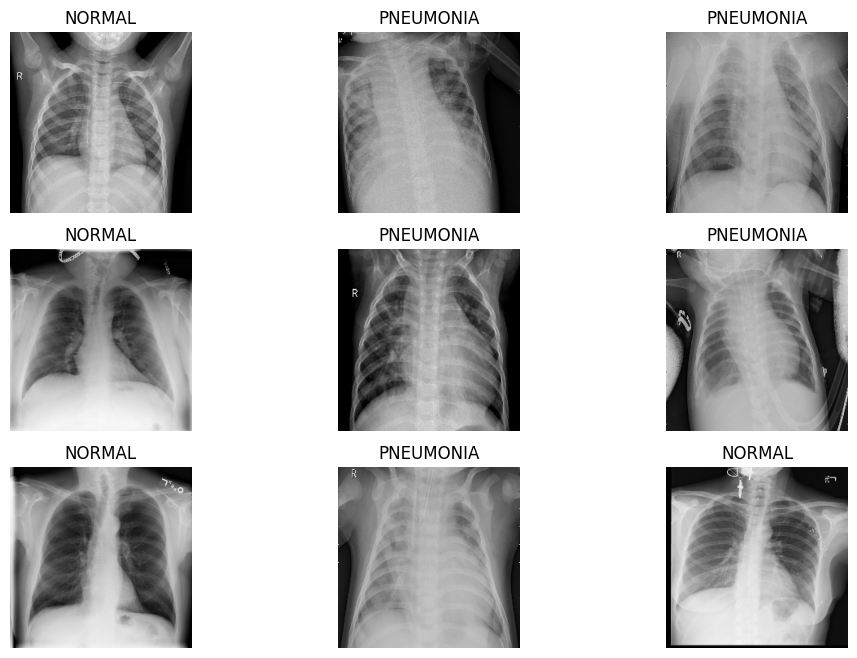

In [121]:
class_names = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        label = int(labels[i].numpy()[0])

        plt.title(class_names[label])

        plt.axis("off")

plt.show()

### Set Dataset Paths

In [122]:
normal_count = len([
    name for name in os.listdir(os.path.join(TRAIN_PATH, "NORMAL"))
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

pneumonia_count = len([
    name for name in os.listdir(os.path.join(TRAIN_PATH, "PNEUMONIA"))
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

total_count = normal_count + pneumonia_count

class_weights = {

    0: total_count / (2 * normal_count),

    1: total_count / (2 * pneumonia_count)

}

print("Class weights:", class_weights)

Class weights: {0: 1.1583587656832826, 1: 0.879732165851146}


### Import Libraries

In [123]:
base_model = DenseNet121(

    weights="imagenet",

    include_top=False,

    input_shape=(224, 224, 3)

)

### Set Trainable Layers

In [124]:
base_model.trainable = False

### Import Libraries

In [125]:
inputs = keras.Input(shape=(224, 224, 3))

# Data augmentation
x = layers.RandomRotation(0.03)(inputs)

x = layers.RandomZoom(0.05)(x)

# Preprocessing for DenseNet121
x = layers.Lambda(
    tf.keras.applications.densenet.preprocess_input,
    name="densenet_preprocessing"
)(x)

# Pretrained DenseNet121
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Binary classification
outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

# Create final model
model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

### Import Libraries

In [126]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

## Train the model

### Import Libraries

In [137]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

### Calculate Class Weights

In [138]:
history = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=15,

    class_weight=class_weights,

    callbacks=callbacks

)

Epoch 1/15
171/171 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.9504 - loss: 0.1471
Epoch 1: val_loss improved from None to 0.09560, saving model to /content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras
171/171 ━━━━━━━━━━━━━━━━━━━━ 49s 287ms/step - accuracy: 0.9482 - loss: 0.1474 - val_accuracy: 0.9693 - val_loss: 0.0956 - learning_rate: 1.0000e-06
Epoch 2/15
171/171 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.9494 - loss: 0.1458
Epoch 2: val_loss did not improve from 0.09560
171/171 ━━━━━━━━━━━━━━━━━━━━ 46s 267ms/step - accuracy: 0.9493 - loss: 0.1447 - val_accuracy: 0.9693 - val_loss: 0.0957 - learning_rate: 1.0000e-06
Epoch 3/15
171/171 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9404 - loss: 0.1477
Epoch 3: val_loss did not improve from 0.09560
171/171 ━━━━━━━━━━━━━━━━━━━━ 45s 262ms/step - accuracy: 0.9404 - loss: 0.1509 - val_accuracy: 0.96

### Set Trainable Layers

In [139]:
base_model.trainable = True

# Freeze most layers
for layer in base_model.layers[:-30]:

    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:

    if isinstance(layer, layers.BatchNormalization):

        layer.trainable = False

### Import Libraries

In [140]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

### Import Libraries

In [141]:
history_fine = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=10,

    class_weight=class_weights,

    callbacks=callbacks

)

model = keras.models.load_model(
    "/content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras"
)

base_model = model.get_layer("densenet121")

Epoch 1/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.9396 - loss: 0.1514
Epoch 1: val_loss improved from 0.09560 to 0.08741, saving model to /content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras
171/171 ━━━━━━━━━━━━━━━━━━━━ 67s 318ms/step - accuracy: 0.9437 - loss: 0.1475 - val_accuracy: 0.9700 - val_loss: 0.0874 - learning_rate: 1.0000e-05
Epoch 2/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.9473 - loss: 0.1421
Epoch 2: val_loss improved from 0.08741 to 0.08126, saving model to /content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/x-ray_Pneumonia_Project/best_pneumonia_model.keras
171/171 ━━━━━━━━━━━━━━━━━━━━ 47s 274ms/step - accuracy: 0.9486 - loss: 0.1330 - val_accuracy: 0.9729 - val_loss: 0.0813 - learning_rate: 1.0000e-05
Epoch 3/10
171/171 ━━━━━━━

### Fine-tune DenseNet121

In [145]:
acc = history.history["accuracy"]

val_acc = history.history["val_accuracy"]

loss = history.history["loss"]

val_loss = history.history["val_loss"]

fine_acc = history_fine.history["accuracy"]

fine_val_acc = history_fine.history["val_accuracy"]

fine_loss = history_fine.history["loss"]

fine_val_loss = history_fine.history["val_loss"]

acc += fine_acc

val_acc += fine_val_acc

loss += fine_loss

val_loss += fine_val_loss

### Plot Training Results

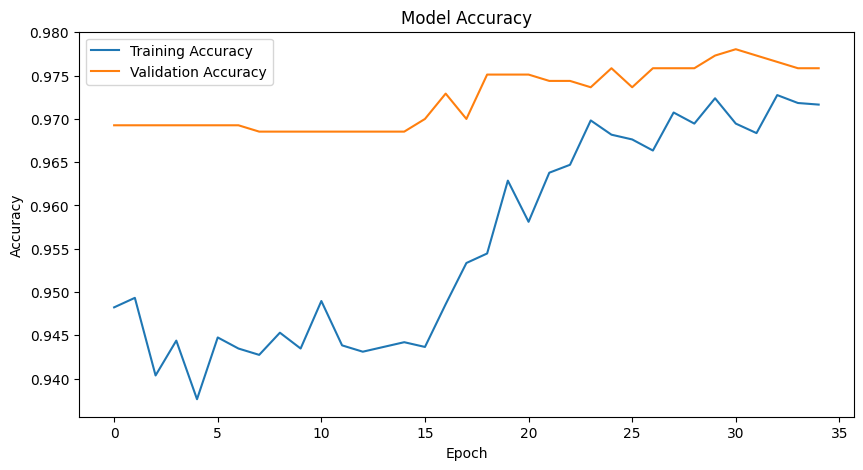

In [146]:
plt.figure(figsize=(10, 5))

plt.plot(acc, label="Training Accuracy")

plt.plot(val_acc, label="Validation Accuracy")

plt.title("Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

### Plot Training Results

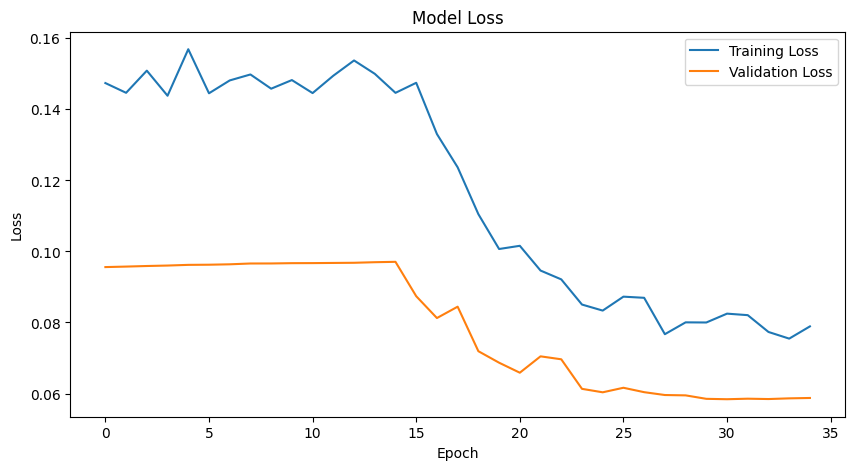

In [147]:
plt.figure(figsize=(10, 5))

plt.plot(loss, label="Training Loss")

plt.plot(val_loss, label="Validation Loss")

plt.title("Model Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

### Evaluate the Model

In [148]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 199ms/step - accuracy: 0.9375 - loss: 0.1703
Test Loss: 0.1703404039144516
Test Accuracy: 0.9375


### Import Libraries

In [149]:
y_true = np.concatenate([

    labels.numpy().ravel()

    for images, labels in test_dataset

])

y_prob = model.predict(test_dataset)

y_pred = (y_prob >= 0.5).astype(int).ravel()

32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step


### Generate Classification Report

In [150]:
print(

    classification_report(

        y_true,

        y_pred,

        target_names=["NORMAL", "PNEUMONIA"]

    )

)

              precision    recall  f1-score   support

      NORMAL       0.99      0.91      0.95       634
   PNEUMONIA       0.87      0.98      0.92       390

    accuracy                           0.94      1024
   macro avg       0.93      0.95      0.94      1024
weighted avg       0.94      0.94      0.94      1024



### Generate Classification Report

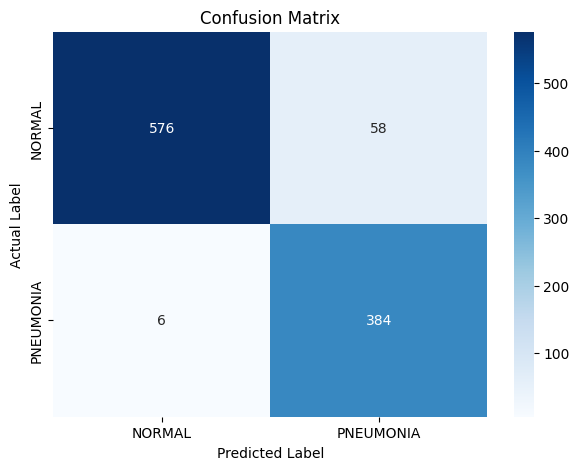

In [151]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=["NORMAL", "PNEUMONIA"],

    yticklabels=["NORMAL", "PNEUMONIA"]

)

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.title("Confusion Matrix")

plt.show()

### Connect Google Drive

In [152]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Save the Trained Model

In [153]:
SAVE_PATH = "/content/drive/MyDrive/x-ray_Pneumonia_Project"

os.makedirs(SAVE_PATH, exist_ok=True)

### Import Libraries

In [154]:
model.save(

    os.path.join(

        SAVE_PATH,

        "pneumonia_densenet121.keras"

    )

)

print("Model saved successfully!")

Model saved successfully!


### Import Libraries

In [155]:
loaded_model = keras.models.load_model(

    "/content/drive/MyDrive/x-ray_Pneumonia_Project/pneumonia_densenet121.keras"

)

print("Model loaded successfully!")

Model loaded successfully!


### Import Libraries

In [156]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/x-ray_Pneumonia_Project/pneumonia_densenet121.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Import Libraries

In [157]:
base_model = loaded_model.get_layer("densenet121")

for layer in base_model.layers[-10:]:
    print(layer.name, layer.output.shape)

conv5_block15_concat (None, 7, 7, 992)
conv5_block16_0_bn (None, 7, 7, 992)
conv5_block16_0_relu (None, 7, 7, 992)
conv5_block16_1_conv (None, 7, 7, 128)
conv5_block16_1_bn (None, 7, 7, 128)
conv5_block16_1_relu (None, 7, 7, 128)
conv5_block16_2_conv (None, 7, 7, 32)
conv5_block16_concat (None, 7, 7, 1024)
bn (None, 7, 7, 1024)
relu (None, 7, 7, 1024)


### Import Libraries

In [158]:
# Select the last convolutional layer
last_conv_layer = base_model.get_layer(
    "conv5_block16_concat"
)

# Create feature extractor
feature_extractor = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        last_conv_layer.output,
        base_model.output
    ]
)

# Find preprocessing and classification layers
preprocessing_layer = loaded_model.get_layer(
    "densenet_preprocessing"
)

gap_layer = next(
    layer for layer in loaded_model.layers
    if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D)
)

dropout_layer = next(
    layer for layer in loaded_model.layers
    if isinstance(layer, tf.keras.layers.Dropout)
)

classifier_layer = loaded_model.layers[-1]

# Create input
inputs = tf.keras.Input(shape=(224, 224, 3))

# Apply preprocessing
x = preprocessing_layer(inputs)

# Extract feature maps
conv_outputs, base_outputs = feature_extractor(
    x,
    training=False
)

# Recreate classification head
x = gap_layer(base_outputs)

x = dropout_layer(x, training=False)

predictions = classifier_layer(x)

# Create Grad-CAM model
grad_model = tf.keras.Model(
    inputs=inputs,
    outputs=[conv_outputs, predictions]
)

print("Grad-CAM model created successfully!")

Grad-CAM model created successfully!


### Import Libraries

In [159]:
def make_gradcam_heatmap(image_array, grad_model):

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_array,
            training=False
        )

        pneumonia_score = predictions[:, 0]

    grads = tape.gradient(
        pneumonia_score,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()


print("Grad-CAM function created!")

Grad-CAM function created!


### Cell 53

### Upload an X-ray Image

In [232]:
from google.colab import files

uploaded = files.upload()

Saving person1018_bacteria_2949.jpeg to person1018_bacteria_2949.jpeg


### Import Libraries

In [233]:
image_path = list(uploaded.keys())[0]

image = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224),
    color_mode="rgb"
)

image_array = tf.keras.utils.img_to_array(image)

image_array = np.expand_dims(
    image_array,
    axis=0
)

print("Image shape:", image_array.shape)

Image shape: (1, 224, 224, 3)


### Visualize X-ray Images

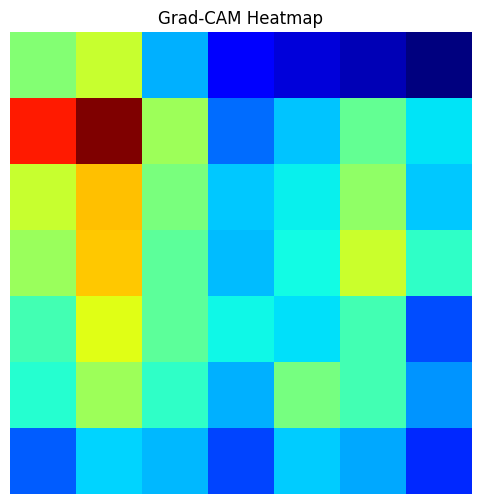

In [234]:
heatmap = make_gradcam_heatmap(
    image_array,
    grad_model
)

plt.figure(figsize=(6, 6))

plt.imshow(heatmap, cmap="jet")

plt.title("Grad-CAM Heatmap")

plt.axis("off")

plt.show()

### Visualize X-ray Images

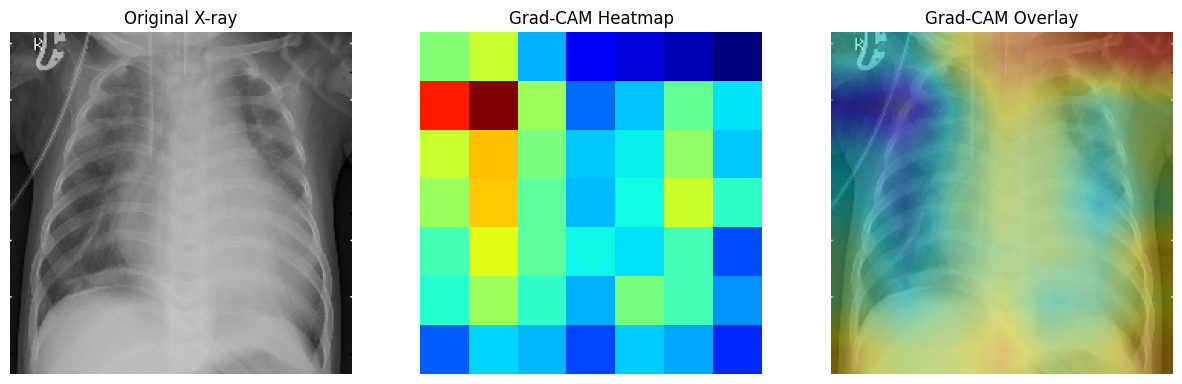

In [235]:
import cv2

# Resize heatmap
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

# Convert heatmap into colour
heatmap_colored = np.uint8(
    255 * heatmap_resized
)

heatmap_colored = cv2.applyColorMap(
    heatmap_colored,
    cv2.COLORMAP_JET
)

# Original image
original_image = image_array[0].astype("uint8")

# Overlay
superimposed_image = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display all three
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(superimposed_image)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.show()

### Visualize X-ray Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


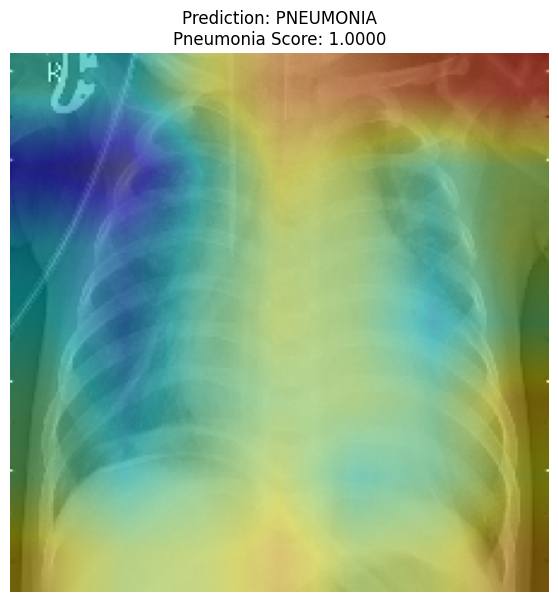

Prediction: PNEUMONIA


In [236]:
prediction = loaded_model.predict(image_array)

pneumonia_score = float(prediction[0][0])

if pneumonia_score >= 0.5:
    result = "PNEUMONIA"
else:
    result = "NORMAL"

plt.figure(figsize=(7, 7))

plt.imshow(superimposed_image)

plt.title(
    f"Prediction: {result}\n"
    f"Pneumonia Score: {pneumonia_score:.4f}"
)

plt.axis("off")

plt.show()

print("Prediction:", result)

### Import Libraries

In [210]:
import numpy as np

# Resize image to 224 × 224
image = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image into numerical array
image_array = tf.keras.utils.img_to_array(image)

# Add batch dimension
image_array = np.expand_dims(image_array, axis=0)

# Predict using trained model
prediction = loaded_model.predict(image_array)

# Get pneumonia score
pneumonia_score = float(prediction[0][0])

# Display result
print("Pneumonia score:", pneumonia_score)

if pneumonia_score >= 0.5:
    print("Prediction: PNEUMONIA")
else:
    print("Prediction: NORMAL")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Pneumonia score: 0.5308423638343811
Prediction: PNEUMONIA


## Adding more normal images for more accurate prediction as per testing random images it failed few times